<a href="https://colab.research.google.com/github/samikshak02/SpamAi/blob/main/spamai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


In [5]:
from google.colab import files
uploaded= files.upload()

Saving spam.csv to spam (1).csv


In [7]:
df = pd.read_csv("spam.csv", encoding="latin-1")

In [8]:
# Keep required columns
df = df[["v1", "v2"]]
df.columns = ["label", "message"]

# Clean dataset
df = df.dropna()
df = df.drop_duplicates()

# Convert labels into numbers
df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})


In [9]:
f = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)

# Dataset information
print("Dataset Shape:", df.shape)
print("\nLabel Counts:")
print(df["label"].value_counts())


Dataset Shape: (5169, 2)

Label Counts:
label
0    4516
1     653
Name: count, dtype: int64


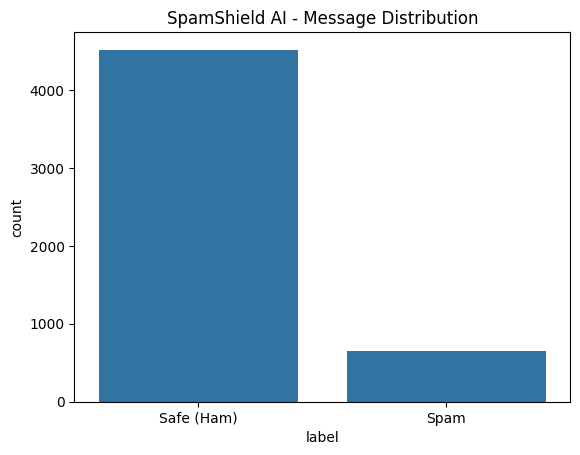

In [10]:
# Visualize spam and safe messages
sns.countplot(x="label", data=df)
plt.xticks([0, 1], ["Safe (Ham)", "Spam"])
plt.title("SpamShield AI - Message Distribution")
plt.savefig("message_distribution.png")
plt.show()

In [11]:
# Input and output
X = df["message"]
y = df["label"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [12]:
# Convert text into numerical features
tfidf = TfidfVectorizer(
    stop_words="english",
    lowercase=True
)

In [14]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Train model
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

# Evaluate model
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("\nModel: Multinomial Naive Bayes")
print(f"Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Safe", "Spam"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)



Model: Multinomial Naive Bayes
Accuracy: 96.62%

Classification Report:
              precision    recall  f1-score   support

        Safe       0.96      1.00      0.98       903
        Spam       0.99      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034



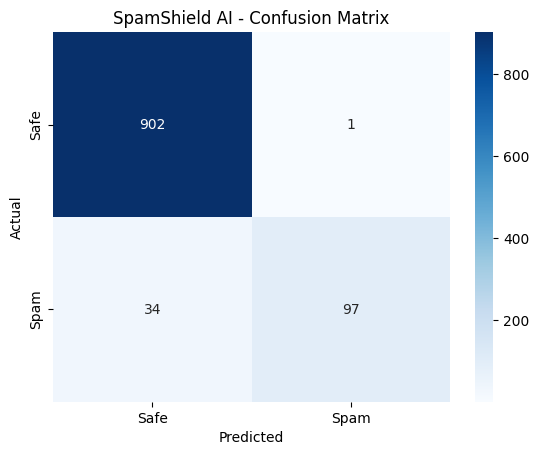

In [20]:
sns.heatmap(
    cm, annot=True, fmt="d",
    cmap="Blues",
    xticklabels=["Safe", "Spam"],
    yticklabels=["Safe", "Spam"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SpamShield AI - Confusion Matrix")
plt.savefig("confusion_matrix.png")
plt.show()

In [21]:
# Save model and vectorizer
joblib.dump(model, "spam_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("\nModel and vectorizer saved successfully!")


Model and vectorizer saved successfully!
